# ¿A quién afectan los incendios? Población a 5 km de los incendios activos del Perú

**Reto D · ¿a quién afecta?** Octubre de 2026 es el octubre con más focos de calor desde
2012. La pregunta de este notebook: **¿cuántas personas viven a 5 km o menos de un
incendio activo, en qué departamentos y cerca de qué incendios?**

| Paso | Qué hacemos |
|---|---|
| 1 | Límites de distritos y departamentos (INEI) |
| 2 | Focos de calor VIIRS de los últimos 7 días en el Perú (NASA FIRMS) |
| 3 | Agrupar focos en **incendios**: focos a ≤ 1 km y ≤ 48 h = un incendio |
| 4 | Raster de población WorldPop 2020 (1 km) |
| 5 | **Raster → tabla**: personas a ≤ 5 km de cada incendio (`zonal_stats`) |
| 6 | Validar, ranking por departamento y mapas |
| 7 | Caso de estudio: Río Tambo (Satipo, Junín), con su área quemada (dNBR) |

Mismo flujo que en la clase de raster (`raster_aplicado.ipynb`): abrir el raster,
revisar `nodata`, agregar a polígonos con `zonal_stats` y validar antes de creer.

## 0 · Preparación

Desde `tarea_clases/`: `uv sync`. Luego, en VS Code, **Select Kernel → Python
Environments → `.venv`**.

In [1]:
import warnings
from pathlib import Path
from urllib.request import urlretrieve

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterstats import zonal_stats

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# Rutas relativas a la raíz del repo, para que funcione en cualquier computadora
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = RAIZ / "data"               # descargas (no se suben a GitHub)
FIGS = RAIZ / "figs"               # mapas para el README
RESULTADOS = RAIZ / "resultados"   # tablas chicas que sí se suben
for carpeta in (DATA, FIGS, RESULTADOS):
    carpeta.mkdir(exist_ok=True)

# UTM 18S mide en metros: ahí se calculan los buffers. Es la zona del centro del Perú;
# en los extremos (Tumbes, Madre de Dios) el error en distancias es de ~1 %.
CRS_METROS = 32718

### Decisiones de método

Todas en un solo lugar, para poder cambiarlas y ver cuánto se mueve el resultado.

In [2]:
DISTANCIA_FOCOS_M = 1000   # dos focos a ≤ 1 km ...
VENTANA_H = 48             # ... y ≤ 48 h de diferencia pertenecen al mismo incendio
MIN_FOCOS = 3              # menos de 3 focos suele ser una quema agrícola puntual
RADIO_M = 5000             # radio de exposición: personas a ≤ 5 km de algún foco

## 1 · Límites de distritos y departamentos

Límites distritales del INEI con UBIGEO (`data/distritos_peru.geojson`, 1 874 distritos,
incluidos los creados en los últimos años, como Megantoni o Vizcatán del Ene). Los
departamentos se arman uniendo (`dissolve`) los distritos.

In [3]:
ARCH_DIST = DATA / "distritos_peru.geojson"
assert ARCH_DIST.exists(), f"Falta {ARCH_DIST}: viene en el repositorio, en data/"

# mismos nombres de columnas que usa el resto del notebook
distritos = (gpd.read_file(ARCH_DIST).to_crs(4326)
             .rename(columns={"ubigeo": "IDDIST", "distrito": "NOMBDIST",
                              "provincia": "NOMBPROV", "departamento": "NOMBDEP"}))
departamentos = distritos.dissolve(by="NOMBDEP", as_index=False)[["NOMBDEP", "geometry"]]
# la base trae huequitos entre distritos vecinos: un buffer de ida y vuelta (~100 m) los cierra
departamentos["geometry"] = departamentos.buffer(0.001).buffer(-0.001)

print(f"{len(distritos):,} distritos · {len(departamentos)} departamentos")

1,874 distritos · 25 departamentos


## 2 · Focos de calor VIIRS en el Perú

El archivo de FIRMS «South America 7d» **cambia todos los días**: siempre trae los últimos
7 días. La primera vez guardamos los focos del Perú en `resultados/focos_peru.csv`, que sí
se sube a GitHub, para que cualquiera obtenga los mismos resultados.

Para volver a descargar, poner `DESCARGAR = True`.

In [4]:
DESCARGAR = False
ARCH_FOCOS = RESULTADOS / "focos_peru.csv"
URL_FIRMS = ("https://firms.modaps.eosdis.nasa.gov/data/active_fire/"
             "suomi-npp-viirs-c2/csv/SUOMI_VIIRS_C2_South_America_7d.csv")

if DESCARGAR or not ARCH_FOCOS.exists():
    crudo = pd.read_csv(URL_FIRMS)
    crudo = gpd.GeoDataFrame(
        crudo,
        geometry=gpd.points_from_xy(crudo.longitude, crudo.latitude),
        crs="EPSG:4326",
    )
    print(f"FIRMS: {len(crudo):,} focos en Sudamérica, "
          f"del {crudo.acq_date.min()} al {crudo.acq_date.max()}")
    # el sjoin deja solo los focos dentro del Perú y les pega su distrito
    en_peru = gpd.sjoin(crudo, distritos[["IDDIST", "NOMBDIST", "NOMBPROV", "NOMBDEP", "geometry"]],
                        predicate="within")
    en_peru.drop(columns=["geometry", "index_right"]).to_csv(ARCH_FOCOS, index=False)

# El CSV guarda los focos tal cual; el distrito se vuelve a asignar con la base de la
# sección 1, así cambiar de base de límites no obliga a descargar FIRMS otra vez.
focos = pd.read_csv(ARCH_FOCOS).drop(columns=["IDDIST", "NOMBDIST", "NOMBPROV", "NOMBDEP"],
                                     errors="ignore")
focos = gpd.GeoDataFrame(
    focos,
    geometry=gpd.points_from_xy(focos.longitude, focos.latitude),
    crs="EPSG:4326",
)
focos = gpd.sjoin(focos, distritos[["IDDIST", "NOMBDIST", "NOMBPROV", "NOMBDEP", "geometry"]],
                  predicate="within")
focos = focos[~focos.index.duplicated()].drop(columns="index_right")   # foco justo en un límite
# acq_time viene como HHMM en UTC (p. ej. 645 = 06:45)
focos["fecha_hora"] = pd.to_datetime(
    focos.acq_date + " " + focos.acq_time.astype(str).str.zfill(4), format="%Y-%m-%d %H%M"
)
print(f"{len(focos):,} focos en el Perú, del {focos.acq_date.min()} al {focos.acq_date.max()}")

3,550 focos en el Perú, del 2026-10-14 al 2026-10-21


### Mirar antes de creer

`confidence` en VIIRS: `low`, `nominal`, `high`. Los de confianza baja suelen ser reflejos
o bordes de nube: se descartan. Un foco de calor **no es** un incendio: es un píxel de
375 m donde el satélite vio algo caliente (también quemas agrícolas).

In [5]:
print(focos.confidence.value_counts(), "\n")
print("focos por día:")
print(focos.groupby("acq_date").size().to_string(), "\n")
print("departamentos con más focos:")
print(focos.NOMBDEP.value_counts().head(10).to_string())

focos = focos[focos.confidence != "low"].reset_index(drop=True)
print(f"\nquedan {len(focos):,} focos de confianza nominal o alta")

confidence
nominal    2926
low         380
high        244
Name: count, dtype: int64 

focos por día:
acq_date
2026-10-14     464
2026-10-15     763
2026-10-16    1385
2026-10-17     174
2026-10-18     263
2026-10-19     212
2026-10-20      84
2026-10-21     205 

departamentos con más focos:
NOMBDEP
UCAYALI       872
JUNIN         408
HUANUCO       349
LORETO        329
CUSCO         245
APURIMAC      214
SAN MARTIN    155
AREQUIPA      152
ANCASH        143
MOQUEGUA       98

quedan 3,170 focos de confianza nominal o alta


## 3 · De focos a incendios

Regla: dos focos a **≤ 1 km y ≤ 48 h** pertenecen al mismo incendio, y si A está pegado a
B y B a C, los tres son un solo incendio (aunque A y C estén lejos). Eso es buscar
**componentes conectados**:

1. `sjoin` con `predicate="dwithin"` encuentra todos los pares de focos a ≤ 1 km.
2. Nos quedamos con los pares a ≤ 48 h.
3. *Union-find*: cada par une a sus dos focos en el mismo grupo.

In [6]:
focos_m = focos.to_crs(CRS_METROS)

pares = gpd.sjoin(
    focos_m[["fecha_hora", "geometry"]],
    focos_m[["fecha_hora", "geometry"]],
    predicate="dwithin", distance=DISTANCIA_FOCOS_M,
)
pares = pares[pares.index < pares.index_right]   # sin (A, A) ni (B, A) repetido
cerca_en_tiempo = (pares.fecha_hora_left - pares.fecha_hora_right).abs() <= pd.Timedelta(hours=VENTANA_H)
pares = pares[cerca_en_tiempo]
print(f"{len(pares):,} pares de focos a ≤ {DISTANCIA_FOCOS_M} m y ≤ {VENTANA_H} h")

# union-find: padre[i] apunta a otro foco del mismo grupo; la raíz identifica al incendio
padre = list(range(len(focos_m)))

def raiz(i):
    while padre[i] != i:
        padre[i] = padre[padre[i]]
        i = padre[i]
    return i

for a, b in zip(pares.index, pares.index_right):
    padre[raiz(a)] = raiz(b)

focos_m["incendio"] = pd.factorize(np.array([raiz(i) for i in range(len(focos_m))]))[0]
print(f"{focos_m.incendio.nunique():,} grupos de focos")

5,543 pares de focos a ≤ 1000 m y ≤ 48 h
1,394 grupos de focos


Una fila por incendio. El departamento, provincia y distrito son los de la **mayoría de sus
focos** (un incendio puede cruzar un límite). "Activo" = al menos un foco en las últimas
24 h del archivo.

In [7]:
mas_comun = lambda s: s.mode().iloc[0]

incendios = focos_m.groupby("incendio").agg(
    focos=("frp", "size"),
    pasadas=("fecha_hora", "nunique"),   # pasadas distintas del satélite
    frp_MW=("frp", "sum"),
    desde=("fecha_hora", "min"),
    hasta=("fecha_hora", "max"),
    departamento=("NOMBDEP", mas_comun),
    provincia=("NOMBPROV", mas_comun),
    distrito=("NOMBDIST", mas_comun),
)
ultimo = focos_m.fecha_hora.max()
incendios["activo_24h"] = incendios.hasta >= ultimo - pd.Timedelta(hours=24)

# puntos de cada incendio unidos en una geometría: sirve para el centro y para el buffer
puntos = focos_m[["incendio", "geometry"]].dissolve(by="incendio").geometry
incendios = gpd.GeoDataFrame(incendios, geometry=puntos.centroid, crs=CRS_METROS)

print(f"grupos con 1 o 2 focos (se descartan): {(incendios.focos < MIN_FOCOS).sum():,}")
incendios = incendios[incendios.focos >= MIN_FOCOS].sort_values("focos", ascending=False)
print(f"incendios con ≥ {MIN_FOCOS} focos: {len(incendios):,} "
      f"({incendios.activo_24h.sum()} activos en las últimas 24 h)")
incendios.drop(columns="geometry").head(10)

grupos con 1 o 2 focos (se descartan): 1,139
incendios con ≥ 3 focos: 255 (21 activos en las últimas 24 h)


,focos,pasadas,frp_MW,desde,hasta,departamento,provincia,distrito,activo_24h
incendio,,,,,,,,,
41,65,9,950.64,2026-10-14 06:54:00,2026-10-18 18:13:00,APURIMAC,ABANCAY,CURAHUASI,False
31,62,6,655.06,2026-10-14 06:52:00,2026-10-16 06:16:00,JUNIN,SATIPO,RIO TAMBO,False
1075,54,4,406.39,2026-10-17 05:57:00,2026-10-18 18:11:00,AREQUIPA,CONDESUYOS,CHICHAS,False
176,51,3,643.93,2026-10-15 06:33:00,2026-10-16 18:49:00,UCAYALI,CORONEL PORTILLO,MANANTAY,False
43,30,4,738.81,2026-10-14 06:54:00,2026-10-17 18:30:00,CUSCO,PARURO,HUANOQUITE,False
285,29,3,580.44,2026-10-15 19:08:00,2026-10-16 18:49:00,JUNIN,TARMA,TAPO,False
1162,29,4,595.27,2026-10-18 18:11:00,2026-10-19 19:34:00,HUANUCO,AMBO,CAYNA,False
181,26,4,"1,437.50",2026-10-15 06:33:00,2026-10-16 18:49:00,UCAYALI,ATALAYA,TAHUANIA,False
173,26,4,275.83,2026-10-15 06:33:00,2026-10-16 18:49:00,UCAYALI,CORONEL PORTILLO,NUEVA REQUENA,False


## 4 · Raster de población: WorldPop 2020

[WorldPop](https://www.worldpop.org/) estima cuántas personas viven en cada píxel de
~1 km, ajustado al total de Naciones Unidas. Es un **modelo**, no un censo: reparte la
población según imágenes satelitales, caminos y asentamientos.

Igual que en clase: antes de agregar, mirar `crs`, resolución y **`nodata`**.

In [8]:
URL_POB = ("https://data.worldpop.org/GIS/Population/Global_2000_2020_1km_UNadj/"
           "2020/PER/per_ppp_2020_1km_Aggregated_UNadj.tif")
ARCH_POB = DATA / "per_ppp_2020_1km.tif"
if not ARCH_POB.exists():
    urlretrieve(URL_POB, ARCH_POB)

with rasterio.open(ARCH_POB) as src:
    pob = src.read(1, masked=True)    # masked: el nodata queda fuera de las cuentas
    crs_pob = src.crs
    nodata_pob = src.nodata
    print(f"tamaño      : {src.width:,} × {src.height:,} píxeles")
    print(f"CRS         : {crs_pob}")
    print(f"resolución  : {src.res[0]:.5f}° ≈ {src.res[0] * 111:.2f} km")
    print(f"nodata      : {nodata_pob}")

print(f"población total del raster: {pob.sum():,.0f}")

tamaño      : 1,522 × 2,199 píxeles
CRS         : EPSG:4326
resolución  : 0.00833° ≈ 0.92 km
nodata      : -99999.0
población total del raster: 32,971,846


**Validación:** el total debería estar cerca de **33 millones** (población del Perú en
2020). Si sale negativo o absurdo, el `nodata` no se está excluyendo.

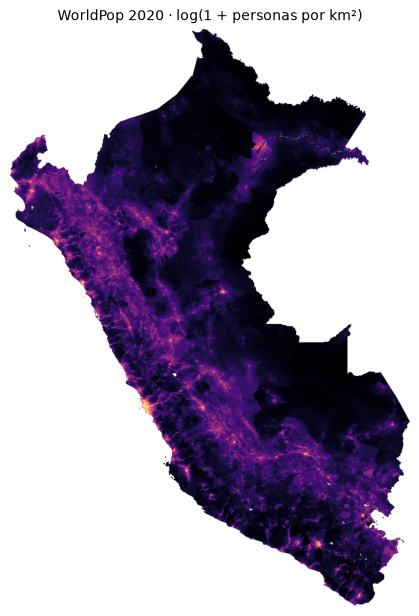

In [9]:
fig, ax = plt.subplots(figsize=(6, 7.5))
ax.imshow(np.log1p(pob), cmap="magma")
ax.set_title("WorldPop 2020 · log(1 + personas por km²)", fontsize=10)
ax.axis("off")
plt.show()

## 5 · Raster → tabla: personas a ≤ 5 km de cada incendio

Para cada incendio: un buffer de 5 km alrededor de **sus focos** (no de su centro) y la
**suma** de los píxeles de población dentro. Como en clase, `sum` y no `mean`: queremos
cuántas personas, no la densidad.

El buffer se calcula en metros (UTM) y luego se pasa al CRS del raster (grados).

`all_touched` es una decisión que importa aquí: con píxeles de 1 km y un círculo de 5 km,
`True` cuenta completos todos los píxeles del borde (sobreestima) y `False` solo los que
tienen el centro adentro. Calculamos ambos y reportamos el rango.

In [10]:
zonas = (puntos.loc[incendios.index].buffer(RADIO_M)
         .to_crs(crs_pob))                                 # mismo CRS que el raster
assert zonas.crs == crs_pob, "CRS distintos: reproyectar antes de cruzar"

for todos, columna in [(False, "personas_5km"), (True, "personas_5km_max")]:
    stats = zonal_stats(zonas, str(ARCH_POB), stats=["sum"], nodata=nodata_pob,
                        all_touched=todos)
    incendios[columna] = [s["sum"] or 0 for s in stats]   # None si no hay píxeles

incendios[["departamento", "distrito", "focos", "activo_24h",
           "personas_5km", "personas_5km_max"]].head(10)

,departamento,distrito,focos,activo_24h,personas_5km,personas_5km_max
incendio,,,,,,
41,APURIMAC,CURAHUASI,65,False,"1,239.91","1,428.42"
31,JUNIN,RIO TAMBO,62,False,"1,056.50","1,276.18"
1075,AREQUIPA,CHICHAS,54,False,185.24,213.01
176,UCAYALI,MANANTAY,51,False,"19,548.46","36,311.36"
43,CUSCO,HUANOQUITE,30,False,"1,315.31","1,508.88"
285,JUNIN,TAPO,29,False,"4,299.03","4,871.18"
1162,HUANUCO,CAYNA,29,False,"2,431.99","2,946.37"
181,UCAYALI,TAHUANIA,26,False,121.99,147.62
173,UCAYALI,NUEVA REQUENA,26,False,92.02,106.89


### Total nacional sin contar dos veces a la misma persona

Si dos incendios están a 3 km, sus círculos se superponen y la gente del medio se cuenta
dos veces al sumar la columna. Para el total nacional unimos todos los círculos primero.

In [11]:
def personas_en(geometrias):
    stats = zonal_stats(geometrias, str(ARCH_POB), stats=["sum"], nodata=nodata_pob)
    return [s["sum"] or 0 for s in stats]

union_total = zonas.union_all()
union_activos = zonas[incendios.activo_24h.values].union_all()

total_sin_doble = personas_en([union_total])[0]
total_activos = personas_en([union_activos])[0] if incendios.activo_24h.any() else 0

print(f"suma simple de la columna          : {incendios.personas_5km.sum():,.0f}")
print(f"total sin doble conteo             : {total_sin_doble:,.0f}")
print(f"solo incendios activos (últ. 24 h) : {total_activos:,.0f}")

suma simple de la columna          : 765,650
total sin doble conteo             : 695,812
solo incendios activos (últ. 24 h) : 17,023


## 6 · Validar antes de creer

¿Los incendios con más gente cerca tienen sentido? Deberían ser los que están junto a
ciudades (p. ej. Manantay, en Pucallpa, o incendios cerca de capitales de provincia).
Si sale uno en medio de la selva sin pueblos, hay que mirar por qué.

In [12]:
top = incendios.sort_values("personas_5km", ascending=False).head(10)
print(top[["departamento", "provincia", "distrito", "focos", "pasadas", "frp_MW",
           "personas_5km", "activo_24h"]].to_string())

         departamento         provincia     distrito  focos  pasadas  frp_MW  personas_5km  activo_24h
incendio                                                                                              
1112      LA LIBERTAD          TRUJILLO    HUANCHACO      3        1    8.01    131,090.75       False
833           UCAYALI  CORONEL PORTILLO  YARINACOCHA      5        1   23.61    103,648.68       False
552          APURIMAC           ABANCAY      ABANCAY     11        2  231.56     47,156.94       False
176           UCAYALI  CORONEL PORTILLO     MANANTAY     51        3  643.93     19,548.46       False
686           HUANUCO           HUANUCO      HUANUCO      4        1   43.40     15,142.53       False
1208           ANCASH            YUNGAY       YUNGAY      6        2   45.00     14,568.72       False
436           UCAYALI  CORONEL PORTILLO  YARINACOCHA     11        3   99.31     13,993.78       False
975        SAN MARTIN             LAMAS        LAMAS      3        1    6

**Lo que encontramos:** el primero, **Huanchaco** (La Libertad, 131 000 personas), son 3
focos de **una sola pasada nocturna** (18 oct), con ~3 MW cada uno, en el desierto costero
junto a Trujillo, donde casi no hay vegetación que quemar. Lo más probable es una fuente
urbana o industrial (p. ej., quema de residuos), no un incendio forestal.

No lo borramos: lo **marcamos** (`posible_fuente_urbana`) y mostramos cuánto cambia el
total sin él. El siguiente, Yarinacocha (borde de Pucallpa), también es de una sola pasada,
pero son 5 focos de día en una zona de chacras y bosque: es más creíble como quema de
vegetación, aunque no lo podemos confirmar solo con FIRMS.

In [13]:
incendios["posible_fuente_urbana"] = incendios.distrito == "HUANCHACO"

total_sin_urbanas = personas_en([zonas[~incendios.posible_fuente_urbana.values].union_all()])[0]
print(f"total sin doble conteo               : {total_sin_doble:,.0f}")
print(f"sin las posibles fuentes urbanas     : {total_sin_urbanas:,.0f}")

total sin doble conteo               : 695,812
sin las posibles fuentes urbanas     : 564,721


### Ranking por departamento

Mismo cuidado con el doble conteo: los círculos se unen por departamento antes de sumar.
También calculamos la población total de cada departamento con `zonal_stats`, para
expresar la exposición como **% de la población**: 50 000 personas no pesan igual en Lima
que en Madre de Dios.

In [14]:
por_dep = incendios.groupby("departamento").agg(
    incendios=("focos", "size"),
    activos_24h=("activo_24h", "sum"),
    focos=("focos", "sum"),
    frp_MW=("frp_MW", "sum"),
)

zonas_dep = (gpd.GeoDataFrame({"departamento": incendios.departamento.values}, geometry=zonas.values,
                              crs=crs_pob)
             .dissolve(by="departamento"))
por_dep["personas_5km"] = pd.Series(personas_en(zonas_dep.geometry), index=zonas_dep.index)

dep_4326 = departamentos.set_index("NOMBDEP").to_crs(crs_pob)
pob_dep = pd.Series(personas_en(dep_4326.geometry), index=dep_4326.index)
por_dep["poblacion_dep"] = pob_dep.reindex(por_dep.index)
por_dep["%_expuesta"] = 100 * por_dep.personas_5km / por_dep.poblacion_dep

por_dep = por_dep.sort_values("personas_5km", ascending=False)
por_dep

,incendios,activos_24h,focos,frp_MW,personas_5km,poblacion_dep,%_expuesta
departamento,,,,,,,
UCAYALI,65,5,449,"8,699.18","149,761.05","574,908.69",26.05
LA LIBERTAD,4,0,17,147.05,"135,742.50","1,930,024.38",7.03
HUANUCO,32,0,177,"2,873.69","74,070.98","845,949.75",8.76
APURIMAC,14,0,165,"3,383.19","63,939.95","401,533.59",15.92
CUSCO,24,0,164,"3,273.06","53,163.37","1,294,172.88",4.11
JUNIN,25,3,201,"2,216.28","46,784.16","1,482,049.12",3.16
ANCASH,13,0,82,"1,133.78","44,485.32","1,095,236.75",4.06
SAN MARTIN,9,0,38,264.98,"30,234.62","953,785.31",3.17
HUANCAVELICA,9,1,55,"1,063.20","29,269.83","542,039.56",5.40


### Sensibilidad: ¿cuánto cambia el número si cambio una decisión?

*"La computadora siempre da un número. Ustedes deciden si es creíble."* Recalculamos el
total nacional (sin doble conteo) cambiando una decisión a la vez. Los grupos de focos ya
están armados, así que solo cambian el filtro de `MIN_FOCOS` y el radio del buffer.

In [15]:
focos_por_grupo = focos_m.groupby("incendio").size()

def expuestos(min_focos, radio):
    ids = focos_por_grupo.index[focos_por_grupo >= min_focos]
    circulos = puntos.loc[ids].buffer(radio).to_crs(crs_pob)
    return {"MIN_FOCOS": min_focos, "RADIO_M": radio, "incendios": len(ids),
            "personas": round(personas_en([circulos.union_all()])[0])}

sensibilidad = pd.DataFrame([expuestos(m, r) for m, r in [
    (MIN_FOCOS, 2000), (MIN_FOCOS, RADIO_M), (MIN_FOCOS, 10000), (1, RADIO_M), (5, RADIO_M),
]])
sensibilidad

,MIN_FOCOS,RADIO_M,incendios,personas
0,3,2000,255,107075
1,3,5000,255,695812
2,3,10000,255,2877188
3,1,5000,1394,5289916
4,5,5000,114,344510


## 7 · Mapas

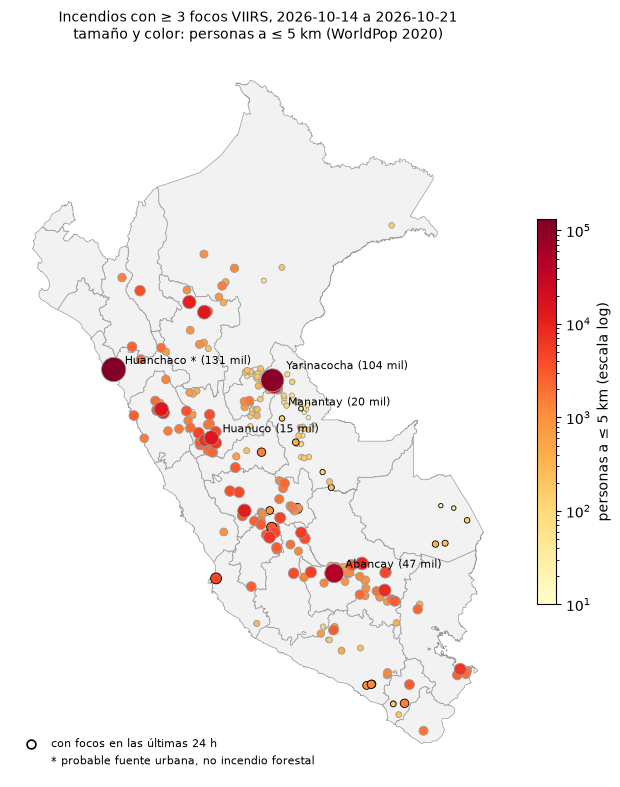

In [16]:
from matplotlib.colors import LogNorm

# todos los incendios con color y tamaño según la gente cerca; los activos, con borde negro
inc_plot = incendios.to_crs(4326).sort_values("personas_5km")   # los grandes quedan encima
inc_plot["personas_color"] = inc_plot.personas_5km.clip(lower=10)  # log no admite 0
tam_punto = 6 + 300 * np.sqrt(inc_plot.personas_5km / inc_plot.personas_5km.max())

fig, ax = plt.subplots(figsize=(8, 10))
departamentos.plot(ax=ax, color="#f2f2f2", edgecolor="#9a9a9a", linewidth=0.5)
inc_plot.plot(ax=ax, column="personas_color", cmap="YlOrRd", markersize=tam_punto,
              norm=LogNorm(vmin=10, vmax=inc_plot.personas_5km.max()),
              edgecolor=np.where(inc_plot.activo_24h, "black", "#999999"), linewidth=0.6,
              legend=True, legend_kwds={"label": "personas a ≤ 5 km (escala log)", "shrink": 0.5})
ax.scatter([], [], s=40, facecolor="white", edgecolor="black", linewidth=1.2,
           label="con focos en las últimas 24 h")

# Yarinacocha y Manantay están juntas (Pucallpa): sus nombres van a lados opuestos
lado = {"YARINACOCHA": (10, 8, "left"), "MANANTAY": (10, -14, "left")}
for _, fila in inc_plot.nlargest(5, "personas_5km").iterrows():
    dx, dy, ha = lado.get(fila.distrito, (8, 4, "left"))
    nombre = fila.distrito.title() + (" *" if fila.posible_fuente_urbana else "")
    ax.annotate(f"{nombre} ({fila.personas_5km / 1000:,.0f} mil)",
                (fila.geometry.x, fila.geometry.y), xytext=(dx, dy),
                textcoords="offset points", fontsize=8, ha=ha)
ax.scatter([], [], s=0, label="* probable fuente urbana, no incendio forestal")
ax.legend(loc="lower left", frameon=False, fontsize=8)
ax.set_title(f"Incendios con ≥ {MIN_FOCOS} focos VIIRS, "
             f"{focos.acq_date.min()} a {focos.acq_date.max()}\n"
             "tamaño y color: personas a ≤ 5 km (WorldPop 2020)", fontsize=10)
ax.axis("off")
plt.savefig(FIGS / "01_mapa_nacional.png", dpi=150, bbox_inches="tight")
plt.show()

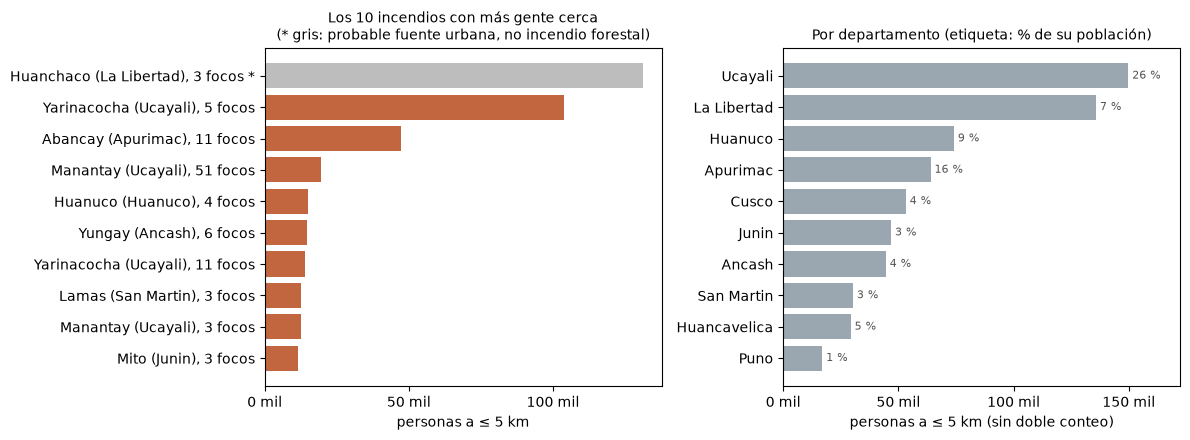

In [17]:
fig, (izq, der) = plt.subplots(1, 2, figsize=(12, 4.5))

top10 = incendios.nlargest(10, "personas_5km").iloc[::-1]
# dos incendios pueden tener el mismo distrito: se distinguen por sus focos
etiquetas = (top10.distrito.str.title() + " (" + top10.departamento.str.title() + "), "
             + top10.focos.astype(str) + " focos"
             + np.where(top10.posible_fuente_urbana, " *", ""))
y = np.arange(len(top10))   # posiciones numéricas: con texto, matplotlib junta etiquetas repetidas
izq.barh(y, top10.personas_5km,
         color=np.where(top10.posible_fuente_urbana, "#bdbdbd", "#c1663f"))
izq.set_yticks(y, etiquetas)
izq.set_xlabel("personas a ≤ 5 km")
izq.set_title("Los 10 incendios con más gente cerca\n"
              "(* gris: probable fuente urbana, no incendio forestal)", fontsize=10)

dep10 = por_dep.head(10).iloc[::-1]
der.barh(dep10.index.str.title(), dep10.personas_5km, color="#9aa7b0")
for y, (personas, pct) in enumerate(zip(dep10.personas_5km, dep10["%_expuesta"])):
    der.text(personas, y, f" {pct:.0f} %", va="center", fontsize=8, color="#555555")
der.set_xlim(right=dep10.personas_5km.max() * 1.15)   # espacio para el %
der.set_xlabel("personas a ≤ 5 km (sin doble conteo)")
der.set_title("Por departamento (etiqueta: % de su población)", fontsize=10)

for eje in (izq, der):
    eje.xaxis.set_major_formatter(lambda v, _: f"{v / 1000:,.0f} mil")
    eje.locator_params(axis="x", nbins=5)
plt.tight_layout()
plt.savefig(FIGS / "02_ranking.png", dpi=150, bbox_inches="tight")
plt.show()

## 8 · Caso de estudio: Río Tambo (Satipo, Junín)

Según Defensa Civil y SERFOR, los incendios en las comunidades asháninkas de Tsyapo y
Tiboreni empezaron el 4 de octubre de 2026 y afectaron unas 1 000 ha de bosque primario y
cultivos ([Mongabay](https://es.mongabay.com/2026/10/peru-medio-centenar-incendios-forestales-trece-regiones-extienden-territorios-indigenas/)).

¿Qué dice nuestro método de ese incendio?

In [18]:
rio_tambo = distritos[(distritos.NOMBDIST == "RIO TAMBO") & (distritos.NOMBPROV == "SATIPO")]
inc_rt = incendios[(incendios.distrito == "RIO TAMBO") & (incendios.provincia == "SATIPO")]
print(inc_rt[["focos", "frp_MW", "desde", "hasta", "personas_5km", "activo_24h"]].to_string())

pob_rt = personas_en(rio_tambo.to_crs(crs_pob).geometry)[0]
print(f"\npoblación del distrito según WorldPop: {pob_rt:,.0f}")

principal = inc_rt.index[0]          # el incendio con más focos del distrito
focos_rt = focos_m[focos_m.incendio == principal]
zona_rt = zonas.loc[[principal]]

          focos  frp_MW               desde               hasta  personas_5km  activo_24h
incendio                                                                                 
31           62  655.06 2026-10-14 06:52:00 2026-10-16 06:16:00      1,056.50       False
1237         12  127.10 2026-10-19 19:34:00 2026-10-20 19:13:00        821.04        True
30            6   11.90 2026-10-14 06:52:00 2026-10-16 06:16:00        493.55       False
249           4   23.47 2026-10-15 19:08:00 2026-10-16 18:49:00      1,098.77       False
1279          4   19.20 2026-10-20 19:13:00 2026-10-20 19:13:00        418.37        True
25            3   12.72 2026-10-14 06:52:00 2026-10-15 19:08:00        679.12       False
26            3    3.27 2026-10-14 06:52:00 2026-10-16 06:16:00      1,356.82       False

población del distrito según WorldPop: 94,779


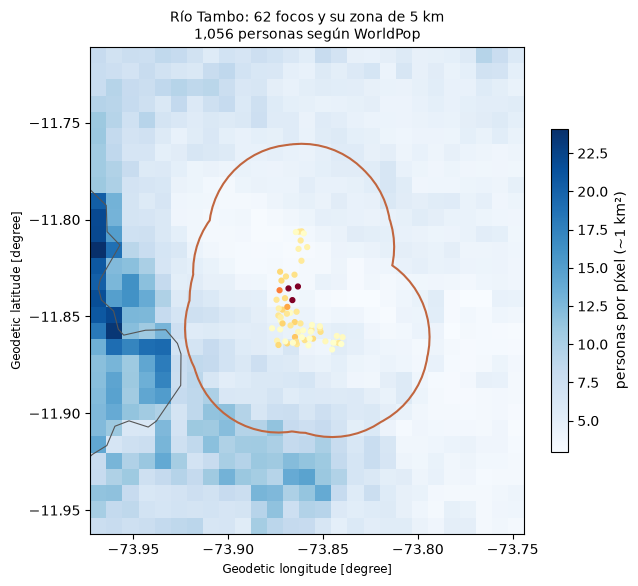

In [19]:
from rasterio.windows import from_bounds

caja = zona_rt.buffer(0.05).total_bounds          # en grados: ~5 km de margen
with rasterio.open(ARCH_POB) as src:
    ventana = from_bounds(*caja, transform=src.transform)
    pob_zona = src.read(1, window=ventana, masked=True)
    izq_, abajo, der_, arriba = src.window_bounds(ventana)

fig, ax = plt.subplots(figsize=(7, 7))
im = ax.imshow(pob_zona, extent=[izq_, der_, abajo, arriba], cmap="Blues")
plt.colorbar(im, ax=ax, shrink=0.6, label="personas por píxel (~1 km²)")
rio_tambo.boundary.plot(ax=ax, color="#555555", linewidth=0.8)
zona_rt.boundary.plot(ax=ax, color="#c1663f", linewidth=1.5)
focos_rt.to_crs(4326).plot(ax=ax, column="frp", cmap="YlOrRd", markersize=12)
ax.set_xlim(izq_, der_)
ax.set_ylim(abajo, arriba)
ax.set_title(f"Río Tambo: {len(focos_rt)} focos y su zona de 5 km\n"
             f"{incendios.loc[principal, 'personas_5km']:,.0f} personas según WorldPop", fontsize=10)
plt.savefig(FIGS / "03_rio_tambo_poblacion.png", dpi=150, bbox_inches="tight")
plt.show()

### Área quemada con dNBR (el mínimo de la entrega)

Sentinel-2 L2A desde Microsoft Planetary Computer, solo en la zona del incendio.

- **NBR** = (NIR − SWIR2) / (NIR + SWIR2) con las bandas B08 y B12. La vegetación sana
  tiene NBR alto; lo quemado, bajo.
- **dNBR** = NBR antes − NBR después. Umbral de quemado: 0,27 (clases USGS).
- Nubes y sombras se enmascaran con la capa **SCL**.

Fechas elegidas midiendo el % de nubes **dentro de la zona** (no el de la escena entera):
23 sep (0 %) antes y 13 oct (19 %) después. Las imágenes del 18 y 20 oct tienen más
nubes todavía.

**Ojo con lo que mide:** la imagen del 13 oct es **anterior** a los focos VIIRS (14 al 16
oct), así que las hectáreas son lo que ya se había quemado desde el inicio del incendio
(4 oct). Además, la nube del 13 oct cae justo sobre el núcleo de los focos: abajo medimos
qué parte de ellos queda tapada.

In [20]:
import odc.stac
import planetary_computer
import pystac_client

FECHA_ANTES = "2026-09-23"
FECHA_DESPUES = "2026-10-13"
UMBRAL = 0.27

zona_dnbr = gpd.GeoSeries([focos_rt.buffer(3000).union_all().envelope], crs=CRS_METROS)
bbox = [round(float(v), 4) for v in zona_dnbr.to_crs(4326).total_bounds]
print("bbox [oeste, sur, este, norte]:", bbox)

catalogo = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

def cargar(fecha):
    items = catalogo.search(collections=["sentinel-2-l2a"], bbox=bbox,
                            datetime=fecha).item_collection()
    ds = odc.stac.load(items, bands=["B08", "B12", "SCL"], bbox=bbox,
                       crs=f"EPSG:{CRS_METROS}", resolution=20, groupby="solar_day")
    return ds.isel(time=0)

nubes = {}   # % de nubes por fecha, se guarda en la sección 9

def nbr(ds, fecha):
    # Desde 2022 los valores traen un desfase de +1000: reflectancia = (DN - 1000) / 10000
    nir = (ds.B08.astype("float32") - 1000) / 10000
    swir = (ds.B12.astype("float32") - 1000) / 10000
    valido = ~ds.SCL.isin([0, 1, 3, 8, 9, 10])   # sin dato, saturado, sombra, nubes, cirros
    nubes[fecha] = 1 - float(valido.mean())
    print(f"{fecha}: nubes/sombras en la zona {nubes[fecha]:.0%}")
    return ((nir - swir) / (nir + swir)).where(valido)

nbr_antes = nbr(cargar(FECHA_ANTES), FECHA_ANTES)
nbr_despues = nbr(cargar(FECHA_DESPUES), FECHA_DESPUES)
dnbr = nbr_antes - nbr_despues

bbox [oeste, sur, este, norte]: [-73.9048, -11.8944, -73.812, -11.7787]


2026-09-23: nubes/sombras en la zona 0%


2026-10-13: nubes/sombras en la zona 19%


In [21]:
HA_PIXEL = 20 * 20 / 10_000    # un píxel de 20 m = 0,04 ha

cortes = [-np.inf, 0.10, 0.27, 0.44, 0.66, np.inf]
clases = ["no quemado", "baja", "moderada-baja", "moderada-alta", "alta"]
valores = dnbr.values[~np.isnan(dnbr.values)]
severidad = (pd.cut(valores, cortes, labels=clases).value_counts().sort_index() * HA_PIXEL)
print(severidad.rename("hectáreas").to_string(), "\n")

ha_quemadas = (valores >= UMBRAL).sum() * HA_PIXEL
print(f"quemado (dNBR ≥ {UMBRAL}): {ha_quemadas:,.0f} ha")
print(f"quemado (dNBR ≥ 0,10): {(valores >= 0.10).sum() * HA_PIXEL:,.0f} ha  ← el umbral importa")

# ¿qué parte de los focos cae donde la imagen "después" no ve nada?
bajo_nube = np.mean([np.isnan(float(dnbr.sel(x=p.x, y=p.y, method="nearest")))
                     for p in focos_rt.geometry])
print(f"focos VIIRS bajo nube o sombra el {FECHA_DESPUES}: {bajo_nube:.0%}")


no quemado      7,177.92
baja            2,354.56
moderada-baja     611.36
moderada-alta     423.60
alta               50.44 

quemado (dNBR ≥ 0.27): 1,085 ha
quemado (dNBR ≥ 0,10): 3,440 ha  ← el umbral importa
focos VIIRS bajo nube o sombra el 2026-10-13: 44%


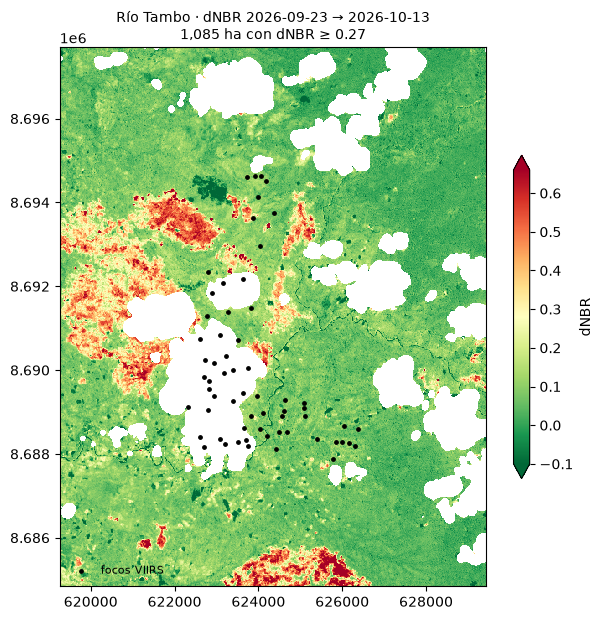

In [22]:
fig, ax = plt.subplots(figsize=(7, 7))
dnbr.plot.imshow(ax=ax, cmap="RdYlGn_r", vmin=-0.1, vmax=0.66,
                 cbar_kwargs={"label": "dNBR", "shrink": 0.6})
focos_rt.plot(ax=ax, color="black", markersize=6, label="focos VIIRS")
ax.legend(loc="lower left", frameon=False, fontsize=8)
ax.set_title(f"Río Tambo · dNBR {FECHA_ANTES} → {FECHA_DESPUES}\n"
             f"{ha_quemadas:,.0f} ha con dNBR ≥ {UMBRAL}", fontsize=10)
ax.set_xlabel("")
ax.set_ylabel("")
plt.savefig(FIGS / "04_rio_tambo_dnbr.png", dpi=150, bbox_inches="tight")
plt.show()

## 9 · Guardar resultados

Tablas chicas que sí se suben a GitHub: las usa el README y, si se hace, el dashboard.

In [23]:
salida = incendios.to_crs(4326)
salida["lon"] = salida.geometry.x.round(4)
salida["lat"] = salida.geometry.y.round(4)
salida.drop(columns="geometry").to_csv(RESULTADOS / "incendios_peru.csv")
por_dep.to_csv(RESULTADOS / "departamentos.csv")
sensibilidad.to_csv(RESULTADOS / "sensibilidad.csv", index=False)

# totales sin doble conteo: no salen de sumar ninguna columna, por eso se guardan aparte
pd.DataFrame({
    "desde": [focos.acq_date.min()], "hasta": [focos.acq_date.max()],
    "incendios": [len(incendios)], "activos_24h": [int(incendios.activo_24h.sum())],
    "personas_5km": [round(total_sin_doble)],
    "personas_5km_sin_fuentes_urbanas": [round(total_sin_urbanas)],
    "personas_5km_activos_24h": [round(total_activos)],
}).to_csv(RESULTADOS / "resumen.csv", index=False)

pd.DataFrame({
    "fecha_antes": [FECHA_ANTES], "fecha_despues": [FECHA_DESPUES],
    "nubes_antes": [round(nubes[FECHA_ANTES], 2)], "nubes_despues": [round(nubes[FECHA_DESPUES], 2)],
    "focos": [len(focos_rt)], "focos_bajo_nube": [round(bajo_nube, 2)], "umbral": [UMBRAL],
    "ha_quemadas": [round(ha_quemadas)],
    "ha_quemadas_010": [round((valores >= 0.10).sum() * HA_PIXEL)],
    "personas_5km": [round(incendios.loc[principal, "personas_5km"])],
    "personas_5km_max": [round(incendios.loc[principal, "personas_5km_max"])],
}).to_csv(RESULTADOS / "rio_tambo.csv", index=False)

# Río Tambo para el dashboard: focos del incendio principal (UTM 18S), clases de severidad
# y el dNBR a 40 m como imagen liviana, con sus bordes para ubicarla
focos_rt.assign(x=focos_rt.geometry.x.round(1), y=focos_rt.geometry.y.round(1))[
    ["fecha_hora", "frp", "x", "y"]].to_csv(RESULTADOS / "focos_rio_tambo.csv", index=False)
severidad.rename("hectareas").rename_axis("clase").reset_index().to_csv(
    RESULTADOS / "rio_tambo_severidad.csv", index=False)
dnbr_web = dnbr.coarsen(x=2, y=2, boundary="trim").mean().sortby("y", ascending=False)
plt.imsave(FIGS / "rio_tambo_dnbr_web.png", dnbr_web.values, cmap="RdYlGn_r", vmin=-0.1, vmax=0.66)
medio = 40 / 2   # los bordes están a medio píxel de los centros
pd.DataFrame({"x_min": [float(dnbr_web.x.min()) - medio], "x_max": [float(dnbr_web.x.max()) + medio],
              "y_min": [float(dnbr_web.y.min()) - medio], "y_max": [float(dnbr_web.y.max()) + medio]}
             ).to_csv(RESULTADOS / "rio_tambo_dnbr_bordes.csv", index=False)
print(sorted(p.name for p in RESULTADOS.iterdir()))

['departamentos.csv', 'focos_peru.csv', 'focos_rio_tambo.csv', 'incendios_peru.csv', 'resumen.csv', 'rio_tambo.csv', 'rio_tambo_dnbr_bordes.csv', 'rio_tambo_severidad.csv', 'sensibilidad.csv']


## 10 · Hallazgos y limitaciones

Números de la corrida con los focos del 14 al 21 de octubre de 2026 (`focos_peru.csv`):

1. **Exposición nacional:** entre el 14 y el 21 de octubre hubo **255 incendios** con ≥ 3
   focos; **~696 000 personas** viven a ≤ 5 km de alguno (**~17 000** de los 21 incendios
   activos en las últimas 24 h). Sin el falso incendio de Huanchaco, ~565 000.
2. **Dónde:** **Ucayali** concentra **~150 000** personas expuestas (**26 %** de su
   población, el mayor porcentaje del país). El primer lugar por incendio, Huanchaco
   (131 000 personas), resultó ser 3 focos de una sola pasada nocturna junto a Trujillo:
   probablemente una fuente urbana y no un incendio forestal. El primero que sí parece
   quema de vegetación es **Yarinacocha, junto a Pucallpa (~104 000 personas)**.
3. **Río Tambo:** **62 focos** (14 al 16 oct), **~1 085 ha** quemadas (dNBR ≥ 0,27,
   23 sep → 13 oct; cerca de las ~1 000 ha oficiales) y solo **~1 060 personas** a ≤ 5 km
   según WorldPop. Fue de los incendios con más focos del país, pero de los que menos
   gente tiene cerca según el dato, aunque afectó a comunidades asháninkas.

**Decisiones que mueven el número** (tabla `sensibilidad` de la sección 6): con un radio de
2 km son ~107 000 personas y con 10 km, ~2,9 millones; con ≥ 1 foco hay 1 394 "incendios"
y 5,3 millones de personas. El dNBR da 3 440 ha con umbral 0,10 y 474 ha con 0,44.

**Limitaciones:**

- Un foco de calor no es un incendio; agrupar con 1 km / 48 h / ≥ 3 focos es una decisión.
  Huanchaco muestra que también hay fuentes de calor urbanas o industriales.
- Vivir a ≤ 5 km es **exposición**, no afectación (humo, pérdida de cultivos, evacuación).
- WorldPop 2020 es un modelo a 1 km: en la Amazonía subestima a las comunidades
  dispersas (como las asháninkas de Río Tambo).
- El archivo de FIRMS solo cubre 7 días: incendios que empezaron antes (Río Tambo, 4 oct)
  aparecen incompletos.
- Las nubes esconden el fuego: VIIRS no ve bajo nubes ni bajo dosel cerrado, y la imagen
  posterior de Sentinel-2 tiene 19 % de nubes en la zona, justo sobre el núcleo: el 44 %
  de los focos cae bajo nube. Además es anterior a esos focos: las hectáreas son un mínimo.
- Las hectáreas se miden en un recuadro alrededor de los focos (+3 km); hay quemado que
  sigue fuera del borde sur.